# Chapter 54: Inflation, Unemployment, Expectations, and Policy Rules

This notebook reruns four worked examples from the chapter: holding unemployment below the natural rate, the Taylor rule, Calvo staggered pricing, and unpleasant monetarist arithmetic. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def accelerationist_path(pi_e0, u_target, u_n, alpha=1.0, years=3):
    """Inflation needed each year to hold u at u_target with full adaptive expectations.

    natural-rate-hypothesis (chapter 54): pi_t = pi_e - alpha (u - u_n), pi_e(t+1) = pi_t.
    Book: pi_e0 = 2, u = 4, u_n = 5, alpha = 1 gives 3, 4, 5. Returns a list of
    (expected, actual) pairs for years 1..years.
    """
    path, pe = [], pi_e0
    for _ in range(years):
        pi = pe - alpha * (u_target - u_n)
        path.append((pe, pi))
        pe = pi
    return path


def unemployment_given_inflation(pi, pi_e, u_n, alpha=1.0):
    """Solve pi = pi_e - alpha (u - u_n) for u. natural-rate-hypothesis: 4 = 4 - (u3 - 5) gives u3 = 5."""
    return u_n + (pi_e - pi) / alpha


def taylor_rule(pi, x, r_star=2.0, pi_star=2.0, a=0.5, b=0.5):
    """Taylor rule i = r* + pi + a (pi - pi*) + b x, returned with its parts.

    taylor-rule (chapter 54): (2, 0) gives 4; (3, 2) gives 6.5; (3, -2) gives 4.5.
    """
    gap_term, out_term = a * (pi - pi_star), b * x
    i = r_star + pi + gap_term + out_term
    return {"i": i, "r_star": r_star, "pi": pi, "gap_term": gap_term, "output_term": out_term, "real": i - pi}


def calvo_price_path(theta, p_old, p_new, k):
    """Linear-average Calvo price path: share at the old price theta^t, P_t = theta^t p_old + (1 - theta^t) p_new.

    calvo-staggered-pricing (chapter 54): theta 0.75, 100 to 108: P1 = 102, share 0.5625, P2 = 103.50.
    Returns a list of (share_old, price) for t = 0..k.
    """
    out = []
    for t in range(k + 1):
        s = theta ** t
        out.append((s, s * p_old + (1 - s) * p_new))
    return out


def debt_path(B0, r, deficit, seigniorage):
    """Real debt B_t = (1 + r) B_{t-1} + D - S_t for each seigniorage entry; returns [B0, B1, ...].

    unpleasant-monetarist-arithmetic (chapter 54): 100, r 0.10, D 5, S (10, 10) gives 105, 110.5;
    S1 = 0 gives 115.
    """
    path = [B0]
    for s in seigniorage:
        path.append((1 + r) * path[-1] + deficit - s)
    return path


plt.rcParams.update(HOUSE_RC)


macro = SimpleNamespace(accelerationist_path=accelerationist_path, unemployment_given_inflation=unemployment_given_inflation, taylor_rule=taylor_rule, calvo_price_path=calvo_price_path, debt_path=debt_path)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'natural-rate-hypothesis': {'u_n': 5,
                             'alpha': 1,
                             'pi_e0': 2,
                             'u_target': 4,
                             'pi': [3, 4, 5],
                             'hold_pi': 4,
                             'u3_hold': 5},
 'taylor-rule': {'r_star': 2,
                 'pi_star': 2,
                 'a': 0.5,
                 'b': 0.5,
                 'i_base': 4,
                 'i_shock': 6.5,
                 'i_slack': 4.5,
                 'increase': 2.5},
 'calvo-staggered-pricing': {'theta': 0.75,
                             'p_old': 100,
                             'p_new': 108,
                             'P1': 102,
                             'share2': 0.5625,
                             'P2': 103.5},
 'unpleasant-monetarist-arithmetic': {'B0': 100,
                                      'r': 0.1,
                                      'D': 5,
                                      'S': 10,
                                      'ceiling': 130,
                                      'B1': 105,
                                      'B2': 110.5,
                                      'B1_tight': 115,
                                      'need2': 131.5,
                                      'min_S2': 1.5,
                                      'S2_tight': 21,
                                      'extra': 11},
 'constructed': {'natural-rate-hypothesis': {'u_target': [3, 5]},
                 'taylor-rule': {'pi': [1, 4]},
                 'calvo-staggered-pricing': {'theta': [0.5, 0.9], 'k': [4]},
                 'unpleasant-monetarist-arithmetic': {'r': [0.05, 0.15], 's1': [5]}}}


def g(x):
    """Short number: whole values without decimals, otherwise two decimals."""
    return num(x, 0) if abs(x - round(x)) < 1e-9 else num(x, 2)


def points(x):
    """Points with singular or plural noun."""
    return f"{g(x)} point" if abs(abs(x) - 1) < 1e-9 else f"{g(x)} points"


def paren(x):
    """Number inside a written sum: negatives in parentheses."""
    return f"({g(x)})" if x < 0 else g(x)


def natural_rate_picture(u_target=4, policy="accelerate"):
    b = BV["natural-rate-hypothesis"]
    u_n, alpha, pe0 = b["u_n"], b["alpha"], b["pi_e0"]
    path = macro.accelerationist_path(pe0, u_target, u_n, alpha, 3)
    years = [0, 1, 2, 3]
    infl = [pe0] + [p for _, p in path]
    unemp = [u_n, u_target, u_target, u_target]
    steps = [f"Year 0: 2 = 2 - (u - 5), so u = 5"]
    for t, (pe, pi) in enumerate(path[:2], start=1):
        steps.append(f"Year {t}: pi = {g(pe)} - ({g(u_target)} - 5) = {g(pe)} + {paren(5 - u_target)} = {g(pi)}")
    if policy == "hold":
        pe3 = path[1][1]
        pi3 = pe3
        u3 = macro.unemployment_given_inflation(pi3, pe3, u_n, alpha)
        infl[3], unemp[3] = pi3, u3
        steps.append(f"Year 3: inflation held at {g(pi3)} = expected {g(pe3)}, so {g(pi3)} = {g(pe3)} - (u3 - 5) "
                     f"gives u3 = {g(u3)}")
    else:
        pe, pi = path[2]
        steps.append(f"Year 3: pi = {g(pe)} - ({g(u_target)} - 5) = {g(pe)} + {paren(5 - u_target)} = {g(pi)}")
    fig, ax = new_figure()
    xs = np.array(years)
    ax.bar(xs - 0.18, infl, width=0.36, color=PALETTE["terracotta"], label="inflation (%)")
    ax.bar(xs + 0.18, unemp, width=0.36, color=PALETTE["navy"], label="unemployment (%)")
    for x, v, u in zip(xs, infl, unemp):
        label(ax, x - 0.18, v, g(v), dx=0, dy=2, ha="center")
        label(ax, x + 0.18, u, g(u), dx=0, dy=2, ha="center")
    ax.axhline(u_n, color=PALETTE["grey"], linestyle="dashed", linewidth=1.2)
    ax.set_xticks(xs, [f"Year {y}" for y in years])
    ax.set_ylim(0, 11)
    ax.legend(loc="upper left", frameon=False)
    ax.set_ylabel("Percent")
    ax.set_xlabel("Year (dashed line: natural rate 5%)")
    metrics = {"Inflation years 1 to 3": f"{g(infl[1])}, {g(infl[2])}, {g(infl[3])}",
               "Unemployment year 3": f"{g(unemp[3])}%",
               "Year-3 policy": "keep accelerating" if policy != "hold" else "hold inflation at the year-2 rate"}
    if u_target == u_n:
        story = "With the target at the natural rate there is no surprise to create, so inflation stays at 2."
    elif policy == "hold":
        story = (f"Holding inflation at {g(infl[3])} leaves no surprise once expectations reach it, so unemployment "
                 f"returns to {g(unemp[3])} percent.")
    else:
        story = ("Each year inflation must exceed the rate already expected, so it keeps "
                 + ("rising." if u_target < u_n else "falling."))
    interp = f"{steps[1]}; {steps[2]}; {steps[3]}. {story}"
    alt = (f"Bars of inflation and unemployment for years 0 to 3. Inflation: {', '.join(g(v) for v in infl)}. "
           f"Unemployment: {', '.join(g(u) for u in unemp)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def taylor_picture(pi=3, x=2):
    b = BV["taylor-rule"]
    t = macro.taylor_rule(pi, x, b["r_star"], b["pi_star"], b["a"], b["b"])
    base = macro.taylor_rule(2, 0)["i"]
    fig, ax = new_figure()
    parts = [("r* = 2", t["r_star"], "grey"), (f"inflation {g(pi)}", t["pi"], "terracotta"),
             (f"0.5(pi - 2) = {g(t['gap_term'])}", t["gap_term"], "gold"),
             (f"0.5 x = {g(t['output_term'])}", t["output_term"], "navy")]
    pos, neg = 0.0, 0.0
    for name, v, col in parts:
        if v >= 0:
            ax.bar([0], [v], bottom=[pos], width=0.5, color=PALETTE[col], label=name)
            pos += v
        else:
            ax.bar([0], [v], bottom=[neg], width=0.5, color=PALETTE[col], label=name)
            neg += v
    ax.scatter([0], [t["i"]], marker="D", s=50, color=PALETTE["ink"], zorder=5)
    label(ax, 0, t["i"], f"i = {g(t['i'])}%", dx=30, dy=0, va="center")
    ax.scatter([1.2], [t["real"]], marker="o", s=50, color=PALETTE["teal"], zorder=5)
    label(ax, 1.2, t["real"], f"real rate i - pi = {g(t['real'])}", col="teal", dx=0, dy=-8, ha="center", va="top")
    hline(ax, base, "baseline 4%", col="grey", x_frac=0.55)
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks([0, 1.2], ["Policy rate", "Real rate"])
    ax.set_xlim(-0.6, 2.6)
    ax.set_ylim(-2.5, 11)
    ax.legend(loc="upper right", frameon=False)
    ax.set_ylabel("Percent")
    ax.set_xlabel("Taylor rule parts")
    calc = (f"i = 2 + {g(pi)} + 0.5({g(pi)} - 2) + 0.5({g(x)}) = 2 + {g(pi)} + {paren(t['gap_term'])} + "
            f"{paren(t['output_term'])} = {g(t['i'])}")
    d = t["i"] - base
    metrics = {"Policy rate i": f"{g(t['i'])}%", "Change from 4% baseline": f"{'+' if d > 0 else ''}{points(d)}",
               "Real rate i - pi": f"{g(t['real'])}%"}
    interp = (f"{calc} percent, {points(abs(d))} {'above' if d > 0 else 'below'} the 4 percent baseline. "
              if abs(d) > 1e-9 else f"{calc} percent, equal to the 4 percent baseline. ")
    interp += f"The real rate is {g(t['i'])} - {g(pi)} = {g(t['real'])}."
    steps = [calc + "%", f"Change = {g(t['i'])} - 4 = {points(d)}", f"Real rate = {g(t['i'])} - {g(pi)} = {g(t['real'])}"]
    alt = (f"Stacked bar of the Taylor rule parts for inflation {g(pi)} and output gap {g(x)}; the policy rate is "
           f"{g(t['i'])} percent and the real rate {g(t['real'])}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def calvo_picture(theta=0.75, k=2):
    b = BV["calvo-staggered-pricing"]
    path = macro.calvo_price_path(theta, b["p_old"], b["p_new"], k)
    share_k, p_k = path[-1]
    fig, (ax1, ax2) = new_figure(ncols=2)
    ts = list(range(k + 1))
    ax1.plot(ts, [p for _, p in path], color=PALETTE["teal"], marker="o", linewidth=2.2)
    for t, (_, p) in zip(ts, path):
        label(ax1, t, p, num(p), dx=0, dy=-16, ha="center", va="top")
    ax1.axhline(108, color=PALETTE["grey"], linestyle="dashed", linewidth=1.2)
    ax1.set_ylim(96, 110)
    ax1.set_xticks(ts)
    ax1.set_xlim(-0.6, k + 0.6)
    ax1.set_xlabel("Period (dashed: reset price 108)")
    ax1.set_ylabel("Average price (dollars)")
    ax2.bar(ts, [s for s, _ in path], color=PALETTE["navy"], width=0.55)
    for t, (s, _) in zip(ts, path):
        label(ax2, t, s, num(s, 4), dx=0, dy=2, ha="center")
    ax2.set_ylim(0, 1.2)
    ax2.set_xticks(ts)
    ax2.set_xlabel("Period")
    ax2.set_ylabel("Share still at 100")
    th = num(theta, 2)
    steps = [f"Share still at 100 after {k} = {th}^{k} = {num(share_k, 4)}",
             f"P{k} = {num(share_k, 4)}(100) + {num(1 - share_k, 4)}(108) = {num(100 * share_k)} + "
             f"{num(108 * (1 - share_k))} = {num(p_k)}"]
    if k >= 1:
        s1, p1 = path[1]
        steps.insert(0, f"P1 = {num(1 - s1, 2)}(108) + {num(s1, 2)}(100) = {num(108 * (1 - s1))} + {num(100 * s1)} = {num(p1)}")
    half = p_k - 100 - 4
    if share_k <= 1e-12:
        where = "all the way"
    else:
        where = ("more than halfway" if half > 1e-9 else ("exactly halfway" if abs(half) <= 1e-9 else "less than halfway"))
    per = "period" if k == 1 else "periods"
    metrics = {f"P after {k} {per}": num(p_k), "Share still at 100": num(share_k, 4), "Progress to 108": where}
    interp = "; ".join(steps) + f". After {k} {per} the average price is {where} from 100 to 108."
    alt = (f"Average price path from 100 toward 108 with theta {th}: {', '.join(num(p) for _, p in path)}. Bars show "
           f"the share of firms still at 100.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def arithmetic_picture(r=0.10, s1=0):
    b = BV["unpleasant-monetarist-arithmetic"]
    B0, D, S, cap = b["B0"], b["D"], b["S"], b["ceiling"]
    R = 1 + r
    base = macro.debt_path(B0, r, D, [S, S])
    tight = macro.debt_path(B0, r, D, [s1])
    need = R * tight[1] + D
    s2 = need - base[2]
    min_cap = max(0.0, need - cap)
    fig, ax = new_figure()
    names = ["B0", "B1", "Year-2 need", "Baseline B2"]
    vals = [B0, tight[1], need, base[2]]
    cols = ["grey", "navy", "terracotta", "teal"]
    ax.bar(range(4), vals, color=[PALETTE[c] for c in cols], width=0.6)
    for i, v in enumerate(vals):
        label(ax, i, v, num(v), dx=0, dy=2, ha="center")
    hline(ax, cap, "ceiling 130", col="terracotta", x_frac=0.02)
    ax.set_xticks(range(4), names)
    ax.set_ylim(0, 175)
    ax.set_ylabel("Real debt (billion dollars)")
    ax.set_xlabel(f"Year-1 seigniorage {num(s1, 0)}, real rate {num(100 * r, 0)}%")
    r_s = num(R, 2)
    steps = [f"B1 = {r_s}(100) + 5 - {num(s1, 0)} = {num(tight[1])}",
             f"Year-2 need = {r_s}({num(tight[1])}) + 5 = {num(R * tight[1])} + 5 = {num(need)}",
             f"Baseline B2 = {r_s}({num(base[1])}) + 5 - 10 = {num(base[2])}",
             f"Seigniorage to return to baseline = {num(need)} - {num(base[2])} = {num(s2)}",
             f"Minimum for the ceiling = {num(need)} - 130 = {num(need - cap)}" if need > cap
             else f"Need {num(need)} is within the ceiling of 130, so no seigniorage is required for it"]
    extra = s2 - S
    metrics = {"B1": num(tight[1]), "Year-2 need": num(need), "Minimum seigniorage for the ceiling": num(min_cap),
               "Seigniorage to return to baseline": num(s2), "Above baseline year-2 seigniorage": num(extra)}
    postponed = S - s1
    if postponed > 0:
        why = (f"Postponing {num(postponed, 0)} of seigniorage costs {num(extra)} in year 2: the {num(postponed, 0)} "
               f"plus {num(100 * r, 0)} percent interest, {num(postponed, 0)} x {r_s} = {num(postponed * R)}.")
    else:
        why = "Nothing is postponed, so year 2 needs only the baseline 10."
    interp = f"{steps[0]}; {steps[1]}; {steps[3]}. {why}"
    alt = (f"Bars of real debt: B0 100, B1 {num(tight[1])}, year-2 need {num(need)} and baseline B2 {num(base[2])}, "
           f"against a 130 ceiling.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Natural-rate hypothesis: chasing low unemployment

The natural rate is 5 percent, $\alpha=1$ and expectations adapt fully each year. The Phillips relation is

$$\pi_t=\pi_t^e-\alpha(u_t-u_t^n)+s_t,$$

so holding $u=4$ needs $\pi_1=2-(4-5)=3$, then 4, then 5.

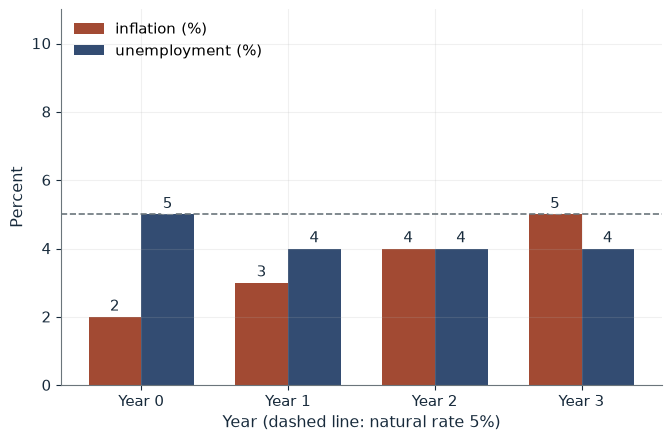

Inflation years 1 to 3  3, 4, 5
Unemployment year 3     4%
Year-3 policy           keep accelerating

Worked steps:
  1. Year 0: 2 = 2 - (u - 5), so u = 5
  2. Year 1: pi = 2 - (4 - 5) = 2 + 1 = 3
  3. Year 2: pi = 3 - (4 - 5) = 3 + 1 = 4
  4. Year 3: pi = 4 - (4 - 5) = 4 + 1 = 5

Year 1: pi = 2 - (4 - 5) = 2 + 1 = 3; Year 2: pi = 3 - (4 - 5) = 3 + 1 = 4; Year 3: pi = 4 - (4 - 5) = 4 + 1 = 5. Each year inflation must exceed the rate already expected, so it keeps rising.


In [2]:
show(natural_rate_picture(u_target=4, policy='accelerate'))

Change one input, `u_target`, and hold the others at the book's values:

In [3]:
sweep(natural_rate_picture, 'u_target', [3, 4, 5], {'policy': 'accelerate'}, ['Inflation years 1 to 3', 'Unemployment year 3'])

u_target | Inflation years 1 to 3 | Unemployment year 3
3 | 4, 6, 8 | 3%
4 | 3, 4, 5 | 4%
5 | 2, 2, 2 | 5%


Inflation must rise 3, 4, 5 to hold unemployment at 4. If inflation is held at 4 in year 3 (`policy='hold'`), $4=4-(u_3-5)$ gives $u_3=5$: the gain disappears.

## 2. Taylor rule: one rule, two signals

With $r^*=2$, target inflation 2 and weights 0.5:

$$i=2+3+0.5(3-2)+0.5(2)=6.5\%.$$

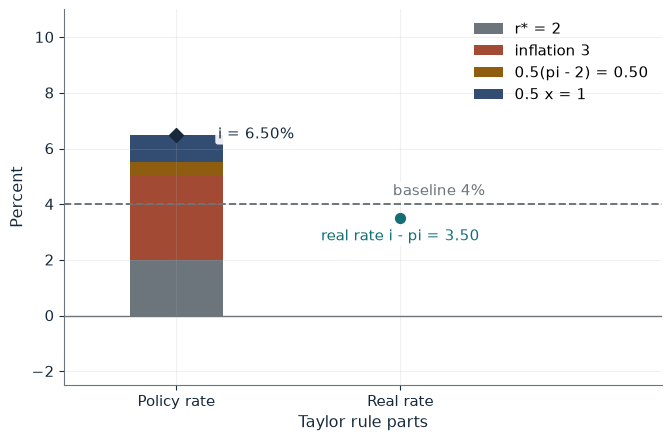

Policy rate i            6.50%
Change from 4% baseline  +2.50 points
Real rate i - pi         3.50%

Worked steps:
  1. i = 2 + 3 + 0.5(3 - 2) + 0.5(2) = 2 + 3 + 0.50 + 1 = 6.50%
  2. Change = 6.50 - 4 = 2.50 points
  3. Real rate = 6.50 - 3 = 3.50

i = 2 + 3 + 0.5(3 - 2) + 0.5(2) = 2 + 3 + 0.50 + 1 = 6.50 percent, 2.50 points above the 4 percent baseline. The real rate is 6.50 - 3 = 3.50.


In [4]:
show(taylor_picture(pi=3, x=2))

Change one input, `x`, and hold the others at the book's values:

In [5]:
sweep(taylor_picture, 'x', [-2, 0, 2], {'pi': 3}, ['Policy rate i', 'Real rate i - pi'])

x | Policy rate i | Real rate i - pi
-2 | 4.50% | 1.50%
0 | 5.50% | 2.50%
2 | 6.50% | 3.50%


The rate is 6.5 percent, 2.5 points above the 4 percent baseline. With the same inflation and a gap of -2 the rule gives 4.5.

## 3. Calvo staggered pricing: prices that reset a few at a time

With $\theta=0.75$, firms move from 100 to 108 dollars a quarter at a time:

$$P_2=0.5625(100)+0.4375(108)=103.50$$

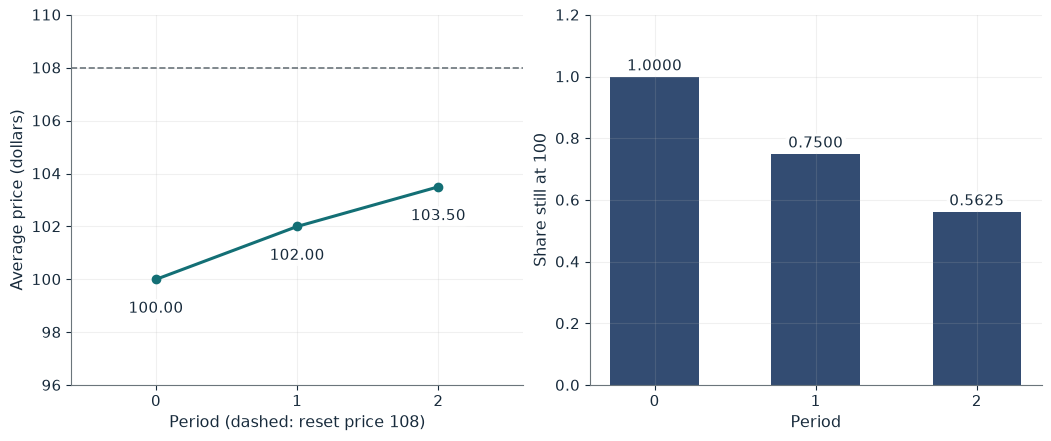

P after 2 periods   103.50
Share still at 100  0.5625
Progress to 108     less than halfway

Worked steps:
  1. P1 = 0.25(108) + 0.75(100) = 27.00 + 75.00 = 102.00
  2. Share still at 100 after 2 = 0.75^2 = 0.5625
  3. P2 = 0.5625(100) + 0.4375(108) = 56.25 + 47.25 = 103.50

P1 = 0.25(108) + 0.75(100) = 27.00 + 75.00 = 102.00; Share still at 100 after 2 = 0.75^2 = 0.5625; P2 = 0.5625(100) + 0.4375(108) = 56.25 + 47.25 = 103.50. After 2 periods the average price is less than halfway from 100 to 108.


In [6]:
show(calvo_picture(theta=0.75, k=2))

Change one input, `theta`, and hold the others at the book's values:

In [7]:
sweep(calvo_picture, 'theta', [0.0, 0.5, 0.75, 0.9], {'k': 2}, ['P after 2 periods', 'Share still at 100'])

theta | P after 2 periods | Share still at 100
0.0 | 108.00 | 0.0000
0.5 | 106.00 | 0.2500
0.75 | 103.50 | 0.5625
0.9 | 101.52 | 0.8100


P1 = 102 and P2 = 103.50, still less than halfway to 108; with theta = 0 the price jumps at once.

## 4. Unpleasant monetarist arithmetic: tight money now, more printing later

Real debt follows

$$B_t=(1+r)B_{t-1}+D_t-S_t,$$

with $B_0=100$, $r=0.10$, $D=5$, a baseline of 10 seigniorage each year and a 130 ceiling.

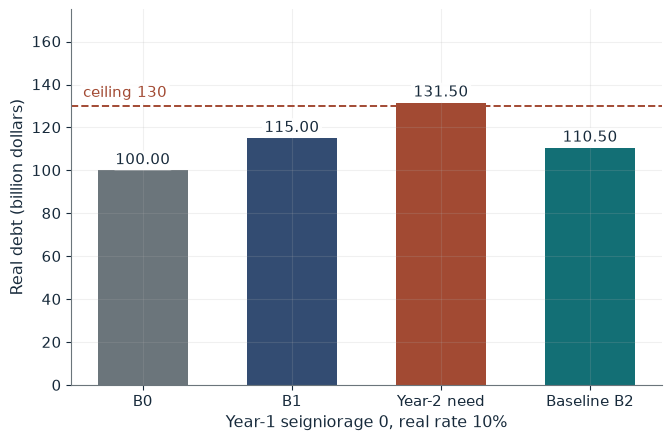

B1                                   115.00
Year-2 need                          131.50
Minimum seigniorage for the ceiling  1.50
Seigniorage to return to baseline    21.00
Above baseline year-2 seigniorage    11.00

Worked steps:
  1. B1 = 1.10(100) + 5 - 0 = 115.00
  2. Year-2 need = 1.10(115.00) + 5 = 126.50 + 5 = 131.50
  3. Baseline B2 = 1.10(105.00) + 5 - 10 = 110.50
  4. Seigniorage to return to baseline = 131.50 - 110.50 = 21.00
  5. Minimum for the ceiling = 131.50 - 130 = 1.50

B1 = 1.10(100) + 5 - 0 = 115.00; Year-2 need = 1.10(115.00) + 5 = 126.50 + 5 = 131.50; Seigniorage to return to baseline = 131.50 - 110.50 = 21.00. Postponing 10 of seigniorage costs 11.00 in year 2: the 10 plus 10 percent interest, 10 x 1.10 = 11.00.


In [8]:
show(arithmetic_picture(r=0.10, s1=0))

Change one input, `s1`, and hold the others at the book's values:

In [9]:
sweep(arithmetic_picture, 's1', [0, 5, 10], {'r': 0.1}, ['B1', 'Year-2 need', 'Seigniorage to return to baseline'])

s1 | B1 | Year-2 need | Seigniorage to return to baseline
0 | 115.00 | 131.50 | 21.00
5 | 110.00 | 126.00 | 15.50
10 | 105.00 | 120.50 | 10.00


Cutting year-1 seigniorage to 0 raises B1 to 115 and the year-2 need to 131.5, so returning to the baseline 110.5 takes 21 of seigniorage: the postponed 10 plus 1 of interest above the usual 10.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

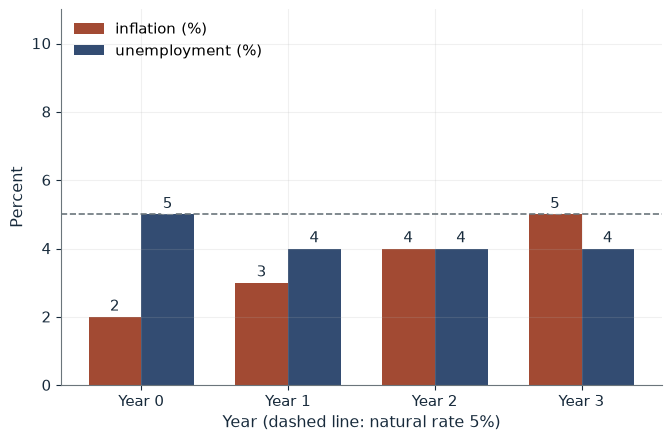

Inflation years 1 to 3  3, 4, 5
Unemployment year 3     4%
Year-3 policy           keep accelerating

Worked steps:
  1. Year 0: 2 = 2 - (u - 5), so u = 5
  2. Year 1: pi = 2 - (4 - 5) = 2 + 1 = 3
  3. Year 2: pi = 3 - (4 - 5) = 3 + 1 = 4
  4. Year 3: pi = 4 - (4 - 5) = 4 + 1 = 5

Year 1: pi = 2 - (4 - 5) = 2 + 1 = 3; Year 2: pi = 3 - (4 - 5) = 3 + 1 = 4; Year 3: pi = 4 - (4 - 5) = 4 + 1 = 5. Each year inflation must exceed the rate already expected, so it keeps rising.


In [10]:
show(natural_rate_picture(u_target=4, policy='accelerate'))

## Practice

**1.** With a 3 percent unemployment target, what inflation is required in year 2?

<details><summary>Answer</summary>

Year 1: 2 - (3 - 5) = 4; year 2: 4 - (3 - 5) = 6 percent.

</details>

**2.** What does the Taylor rule give at inflation 3 and an output gap of -2?

<details><summary>Answer</summary>

2 + 3 + 0.5(3 - 2) + 0.5(-2) = 2 + 3 + 0.5 - 1 = 4.5 percent.

</details>

**3.** At theta = 0.5, what is the average price after two periods?

<details><summary>Answer</summary>

0.5^2 = 0.25 still at 100, so P2 = 0.25(100) + 0.75(108) = 25 + 81 = 106.

</details>